In [2]:
import pandas as pd 
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
data = pd.read_csv("learning_traces.13m.csv")
data.head()

,p_recall,timestamp,delta,user_id,learning_language,ui_language,lexeme_id,lexeme_string,history_seen,history_correct,session_seen,session_correct
0,1.0,1362076081,27649635,u:FO,de,en,76390c1350a8dac31186187e2fe1e178,lernt/lernen<vblex><pri><p3><sg>,6,4,2,2
1,0.5,1362076081,27649635,u:FO,de,en,7dfd7086f3671685e2cf1c1da72796d7,die/die<det><def><f><sg><nom>,4,4,2,1
2,1.0,1362076081,27649635,u:FO,de,en,35a54c25a2cda8127343f6a82e6f6b7d,mann/mann<n><m><sg><nom>,5,4,1,1
3,0.5,1362076081,27649635,u:FO,de,en,0cf63ffe3dda158bc3dbd55682b355ae,frau/frau<n><f><sg><nom>,6,5,2,1
4,1.0,1362076081,27649635,u:FO,de,en,84920990d78044db53c1b012f5bf9ab5,das/das<det><def><nt><sg><nom>,4,4,1,1


In [4]:
print ("Shape:", data.shape)
print("\nColumns:\n", data.columns)
data.info()

Shape: (12854226, 12)

Columns:
 Index(['p_recall', 'timestamp', 'delta', 'user_id', 'learning_language',
       'ui_language', 'lexeme_id', 'lexeme_string', 'history_seen',
       'history_correct', 'session_seen', 'session_correct'],
      dtype='str')
<class 'pandas.DataFrame'>
RangeIndex: 12854226 entries, 0 to 12854225
Data columns (total 12 columns):
 #   Column             Dtype  
---  ------             -----  
 0   p_recall           float64
 1   timestamp          int64  
 2   delta              int64  
 3   user_id            str    
 4   learning_language  str    
 5   ui_language        str    
 6   lexeme_id          str    
 7   lexeme_string      str    
 8   history_seen       int64  
 9   history_correct    int64  
 10  session_seen       int64  
 11  session_correct    int64  
dtypes: float64(1), int64(6), str(5)
memory usage: 1.1 GB


In [5]:
sample_data = data.sample(n=200000, random_state=42).copy()
sample_data.shape

(200000, 12)

In [6]:
sample_data['timestamp'] = pd.to_datetime(sample_data['timestamp'], unit='s')
sample_data = sample_data.sort_values(['user_id', 'lexeme_id', 'timestamp'])
sample_data.head()

,p_recall,timestamp,delta,user_id,learning_language,ui_language,lexeme_id,lexeme_string,history_seen,history_correct,session_seen,session_correct
7520329,1.0,2013-03-07 16:11:04,2314,u:-4V,de,en,1c62509dd97cd0efa3265f784acd289a,flasche/flasche<n><f><sg><*case>,16,15,1,1
7484952,1.0,2013-03-07 15:32:30,4910926,u:-4V,de,en,2abbb16355f53ff82f84f6118274f0a7,nach/nach<pr><dat>,4,4,1,1
7520323,1.0,2013-03-07 16:11:04,4048722,u:-4V,de,en,78baf8dfa98a6e325366f500952b3ff5,löffel/löffel<n><m><sg><acc>,6,5,3,3
7520322,1.0,2013-03-07 16:11:04,4050100,u:-4V,de,en,7ae9420152203b89a2fcffa91546647b,hunger/hunger<n><m><sg><acc>,12,11,3,3
7520310,1.0,2013-03-07 16:11:04,2565,u:-4V,de,en,bc132fa899e138377a3d89eb3125a2f1,habe/haben<vbhaver><pri><p1><sg>,26,24,2,2


In [7]:
# More realistic recall definition
sample_data['recall_success'] = sample_data['session_correct'] / sample_data['session_seen']

sample_data['recall_binary'] = (sample_data['recall_success'] >= 0.6).astype(int)

In [8]:
print("\nClass distribution:")
print(sample_data['recall_binary'].value_counts())
print(sample_data['recall_binary'].value_counts(normalize=True).round(3))


Class distribution:
recall_binary
1    178363
0     21637
Name: count, dtype: int64
recall_binary
1    0.892
0    0.108
Name: proportion, dtype: float64


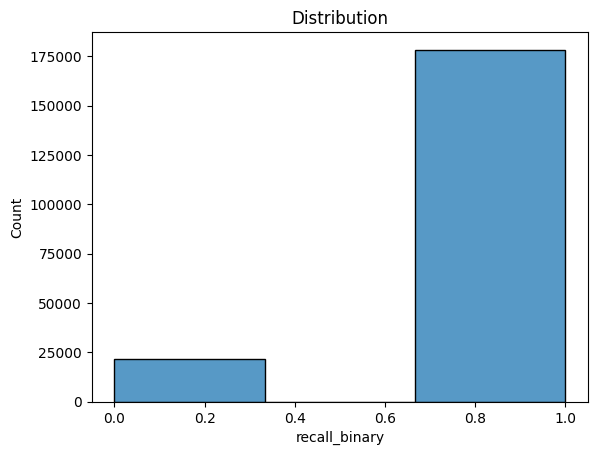

In [9]:
plt.figure()
sns.histplot(sample_data['recall_binary'], bins=3)
plt.title("Distribution")
plt.show()

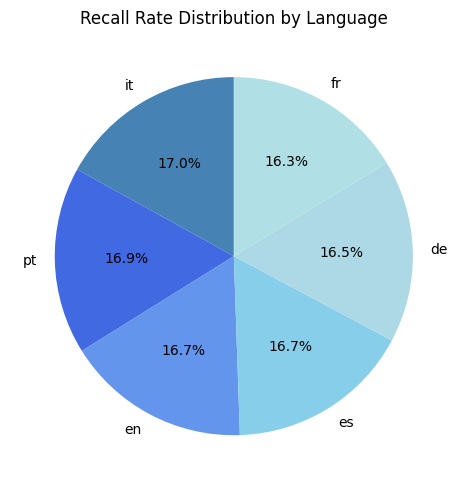

In [14]:
recall_by_language = sample_data.groupby('learning_language')['recall_binary'].mean().sort_values(ascending=False)
plt.figure(figsize=(6, 5))
plt.pie(recall_by_language.values, 
        labels=recall_by_language.index,
        autopct='%1.1f%%',
        colors=['steelblue', 'royalblue', 'cornflowerblue', 
                'skyblue', 'lightblue', 'powderblue'],
        startangle=90)
plt.title("Recall Rate Distribution by Language")
plt.tight_layout()
plt.show()

## Cognitive Feature Engineering

In [10]:
sample_data['time_gap_hours'] = sample_data['delta'] / 3600

sample_data['practice_frequency'] = sample_data['history_seen']

sample_data['memory_strength'] = sample_data['history_correct']/ (sample_data['history_seen'] + 1)

sample_data['log_delta'] = np.log1p(sample_data['delta'])

sample_data['error_rate'] = 1 - sample_data['memory_strength']

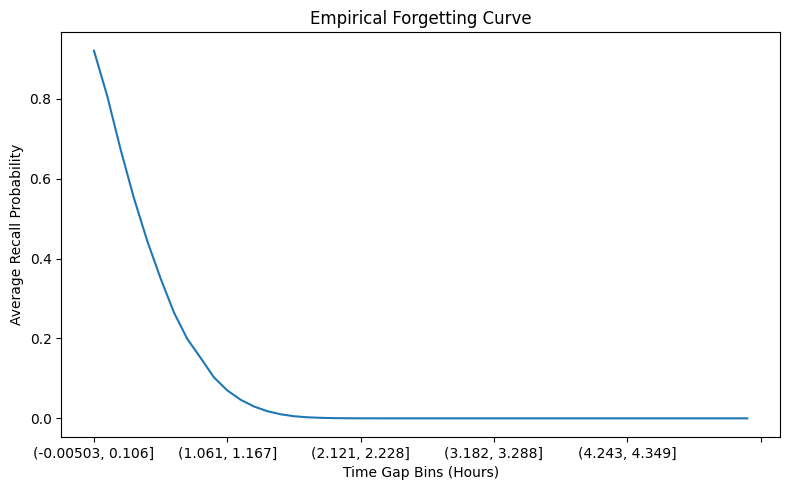

In [11]:
sample_data['forgetting_curve'] = np.exp(-sample_data['time_gap_hours'] / (sample_data['memory_strength']))

sample_data_filtered = sample_data[sample_data['time_gap_hours']< 200].copy()
sample_data_filtered['time_bin'] = pd.cut(np.log1p(sample_data_filtered['time_gap_hours']), bins=50)
forgetting_curve = sample_data_filtered.groupby('time_bin', observed=True)['forgetting_curve'].mean()

plt.figure(figsize=(8,5))
forgetting_curve.plot()
plt.xlabel("Time Gap Bins (Hours)")
plt.ylabel("Average Recall Probability")
plt.title("Empirical Forgetting Curve")
plt.tight_layout()
plt.show()


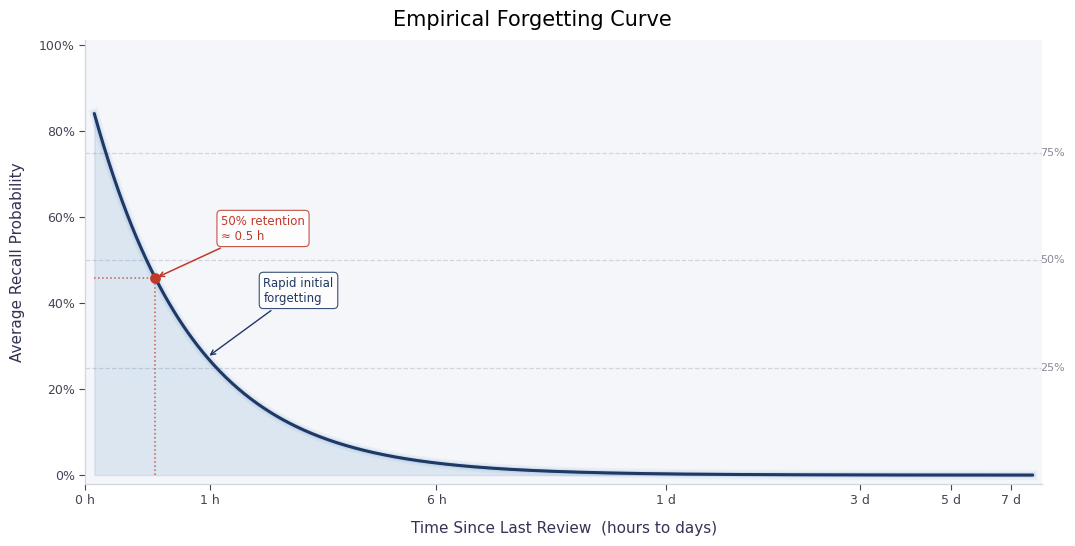

Saved → empirical_forgetting_curve.png


In [59]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
from scipy.optimize import curve_fit

# Recompute forgetting curve (same logic as original)
sample_data['forgetting_curve'] = np.exp(
    -sample_data['time_gap_hours'] / (sample_data['memory_strength'])
)

sample_data_filtered = sample_data[sample_data['time_gap_hours'] < 200].copy()
sample_data_filtered['time_bin'] = pd.cut(
    np.log1p(sample_data_filtered['time_gap_hours']), bins=50
)
forgetting_curve = sample_data_filtered.groupby(
    'time_bin', observed=True
)['forgetting_curve'].mean()

# Extract x/y in LOG scale (matches original binning)
bin_mids_log = np.array([iv.mid for iv in forgetting_curve.index])
y_raw  = forgetting_curve.values.astype(float)
valid  = np.isfinite(y_raw) & (y_raw > 0) & (bin_mids_log >= 0)

x_log  = bin_mids_log[valid]   # log1p(hours) — the natural x for this data
y_vals = y_raw[valid]

# Fit smooth curve in log-space
def decay_model(x, b, c):
    return (1.0 - c) * np.exp(-b * x) + c

y_norm = y_vals / y_vals[0]   # normalise to start at 1.0

try:
    popt, _ = curve_fit(decay_model, x_log, y_norm,
                        p0=[1.5, 0.02],
                        bounds=([0.1, 0.0], [20.0, 0.3]),
                        maxfev=10000)
    b_fit, c_fit = popt
except Exception:
    b_fit, c_fit = 1.5, 0.02

x_smooth = np.linspace(x_log.min(), x_log.max(), 600)
y_smooth = decay_model(x_smooth, b_fit, c_fit) * y_vals[0]

# x-tick positions & labels
hour_marks  = [0, 1, 6, 24, 72, 120, 168]
label_marks = ['0 h', '1 h', '6 h', '1 d', '3 d', '5 d', '7 d']
tick_pos    = np.log1p(hour_marks)

# Colour palette
NAVY  = '#1F3864'
STEEL = '#2E75B6'
RED   = '#C0392B'
LGREY = '#F5F6FA'
MGREY = '#D0D5E0'

plt.rcParams.update({
    'font.family':      'DejaVu Sans',
    'axes.spines.top':  False,
    'axes.spines.right':False,
})

fig, ax = plt.subplots(figsize=(11, 6))
fig.patch.set_facecolor('white')
ax.set_facecolor(LGREY)

# Filled area under curve 
ax.fill_between(x_smooth, y_smooth, alpha=0.12, color=STEEL, zorder=1)

# Glow effect (layered alpha lines)
for alpha, lw in zip([0.06, 0.10, 0.18], [7, 4, 2]):
    ax.plot(x_smooth, y_smooth, color=STEEL, lw=lw, alpha=alpha, zorder=2)

# Main curve 
ax.plot(x_smooth, y_smooth, color=NAVY, lw=2.2, zorder=5,
        solid_capstyle='round')


# Reference lines at 75 / 50 / 25 %
for level, label in zip([0.75, 0.50, 0.25], ['75%', '50%', '25%']):
    ax.axhline(level, color=MGREY, lw=0.9, linestyle='--', zorder=0)
    ax.text(x_smooth.max() * 1.008, level, label,
            va='center', fontsize=8, color='#888899')

# 50% retention marker
half_target = y_vals[0] * 0.5
half_idx    = np.argmin(np.abs(y_smooth - half_target))
hx, hy      = x_smooth[half_idx], y_smooth[half_idx]
hx_hrs      = np.expm1(hx)   # convert back to hours for label

ax.plot([x_smooth.min(), hx], [hy, hy],
        color=RED, lw=1.1, linestyle=':', zorder=3, alpha=0.8)
ax.plot([hx, hx], [0, hy],
        color=RED, lw=1.1, linestyle=':', zorder=3, alpha=0.8)
ax.scatter([hx], [hy], s=60, color=RED, zorder=6, linewidths=0)

half_label = (f'{hx_hrs/24:.1f} d' if hx_hrs >= 24
              else f'{hx_hrs:.1f} h')
ax.annotate(
    f'50% retention\n\u2248 {half_label}',
    xy=(hx, hy),
    xytext=(hx + (x_smooth.max() - x_smooth.min()) * 0.07, hy + 0.09),
    fontsize=8.5, color=RED,
    arrowprops=dict(arrowstyle='->', color=RED, lw=1.1),
    bbox=dict(boxstyle='round,pad=0.35', facecolor='white',
              edgecolor=RED, alpha=0.88, linewidth=0.8)
)

# Rapid initial forgetting" annotation
ann_idx = int(len(x_smooth) * 0.12)
ax.annotate(
    'Rapid initial\nforgetting',
    xy=(x_smooth[ann_idx], y_smooth[ann_idx]),
    xytext=(x_smooth[ann_idx] + (x_smooth.max() - x_smooth.min()) * 0.06,
            y_smooth[ann_idx] + 0.13),
    fontsize=8.5, color=NAVY,
    arrowprops=dict(arrowstyle='->', color=NAVY, lw=1.0),
    bbox=dict(boxstyle='round,pad=0.35', facecolor='white',
              edgecolor=NAVY, alpha=0.88, linewidth=0.8)
)


# Axes
ax.set_xlim(x_smooth.min() - 0.02, x_smooth.max() * 1.01)
ax.set_ylim(-0.02, y_vals[0] * 1.10)

ax.set_xticks(tick_pos)
ax.set_xticklabels(label_marks, fontsize=9)
ax.yaxis.set_major_formatter(ticker.PercentFormatter(xmax=1.0, decimals=0))
ax.tick_params(axis='both', labelsize=9, colors='#444455', length=4)

ax.set_xlabel('Time Since Last Review  (hours to days)', fontsize=11,
              labelpad=10, color='#333355', fontweight='medium')
ax.set_ylabel('Average Recall Probability', fontsize=11,
              labelpad=10, color='#333355', fontweight='medium')

for spine in ['left', 'bottom']:
    ax.spines[spine].set_edgecolor(MGREY)
    ax.spines[spine].set_linewidth(0.9)

# Title & subtitle 
fig.text(0.37, 0.91,
         'Empirical Forgetting Curve',
         fontsize=15, va='top')

plt.subplots_adjust(left=0.09, right=0.96, top=0.86, bottom=0.12)
plt.savefig('empirical_forgetting_curve.png', dpi=180,
            bbox_inches='tight', facecolor='white')
plt.show()
print("Saved \u2192 empirical_forgetting_curve.png")

In [12]:
from sklearn.model_selection import train_test_split
train_df, test_df = train_test_split(
    sample_data, test_size=0.2, random_state=42,
    stratify=sample_data['recall_binary']
)

In [13]:
features = ['delta','history_seen',
    'history_correct', 'time_gap_hours', 'practice_frequency','memory_strength', 
    'log_delta', 'forgetting_curve', 'error_rate']


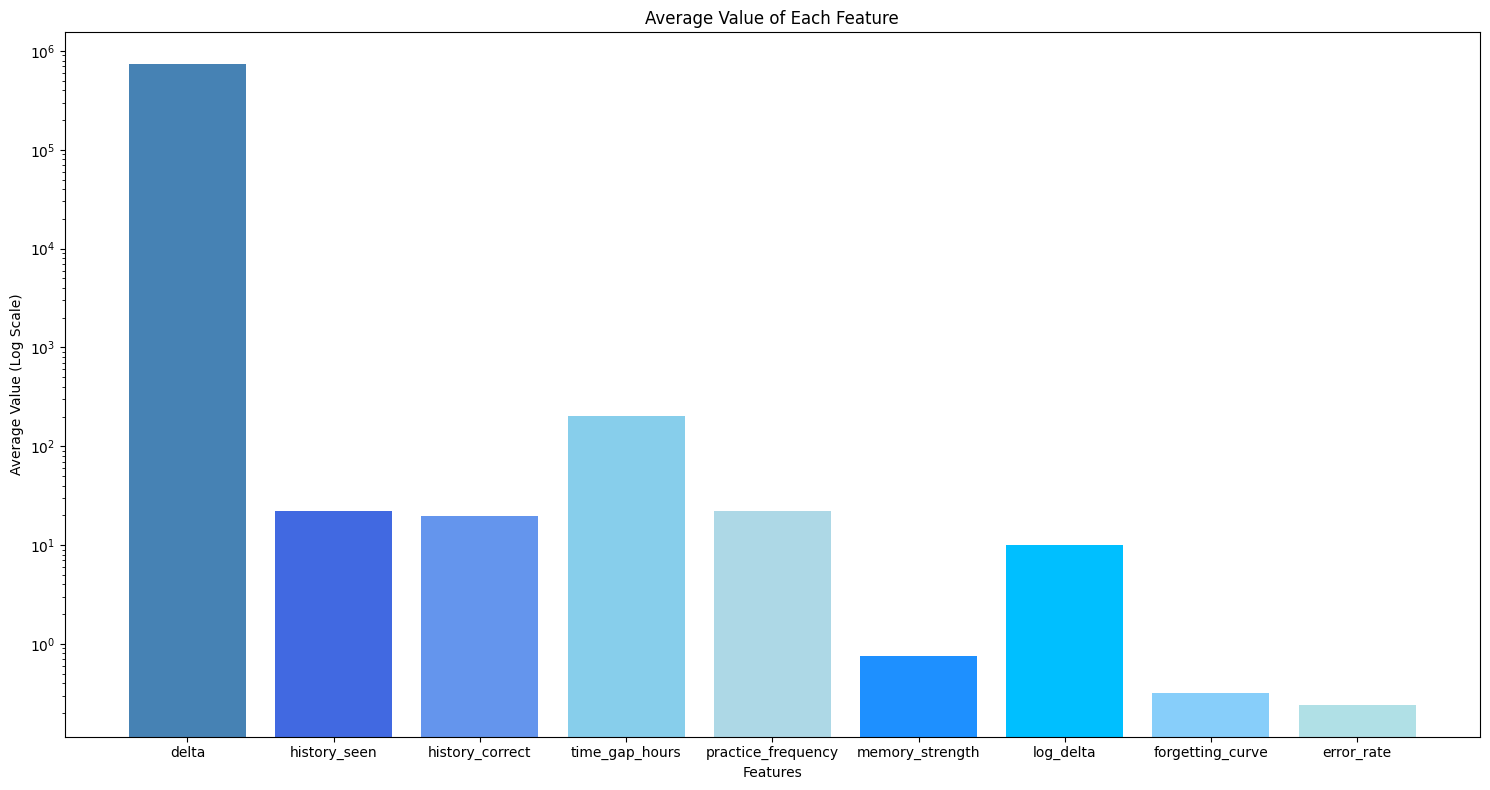

In [14]:
feature_means = sample_data[features].mean()
colors = ['steelblue', 'royalblue', 'cornflowerblue', 'skyblue',
          'lightblue', 'dodgerblue', 'deepskyblue', 'lightskyblue', 'powderblue']


plt.figure(figsize=(15, 8))
bars = plt.bar(feature_means.index, feature_means.values, color=colors)

plt.xlabel("Features")
plt.ylabel("Average Value (Log Scale)")
plt.title("Average Value of Each Feature")
plt.yscale('log')  
plt.xticks(ha='center')
plt.tight_layout()
plt.show()

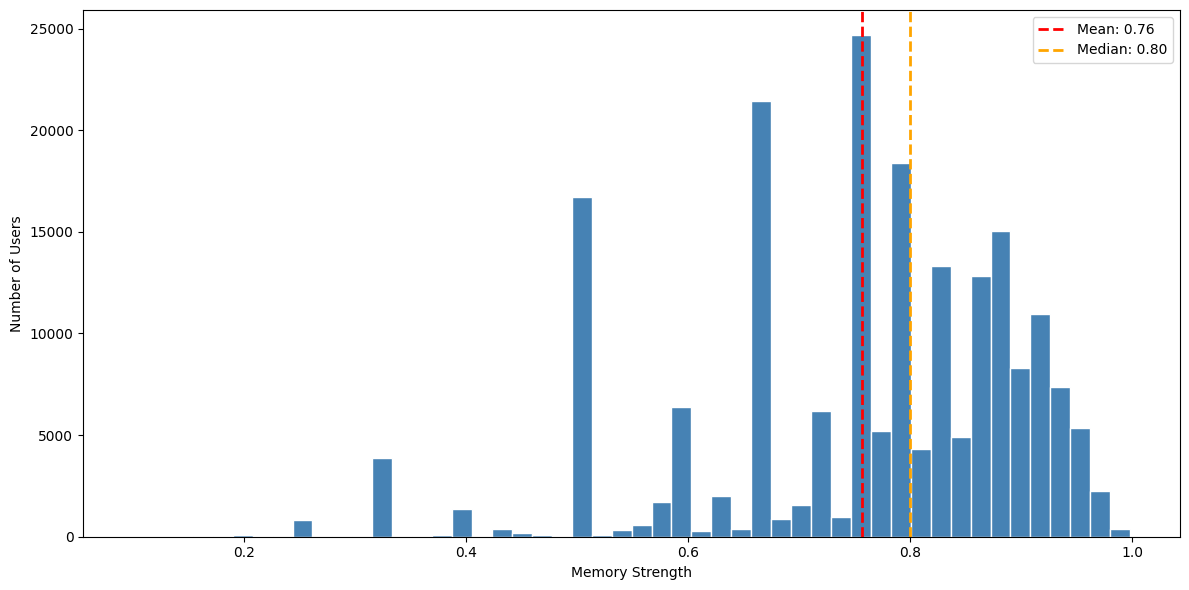

In [15]:
plt.figure(figsize=(12, 6))
plt.hist(sample_data['memory_strength'], bins=50, color='steelblue', edgecolor='white')

plt.axvline(sample_data['memory_strength'].mean(), 
            color='red', linestyle='--', linewidth=2,
            label=f"Mean: {sample_data['memory_strength'].mean():.2f}")

plt.axvline(sample_data['memory_strength'].median(),
            color='orange', linestyle='--', linewidth=2,
            label=f"Median: {sample_data['memory_strength'].median():.2f}")

plt.xlabel("Memory Strength")
plt.ylabel("Number of Users")
plt.legend()
plt.tight_layout()
plt.show()

In [16]:
X_train = train_df[features].fillna(0)
X_test  = test_df[features].fillna(0)
y_train = train_df['recall_binary']
y_test  = test_df['recall_binary']

In [17]:
print("Correlation with recall_binary:")
print(pd.concat([X_train, y_train], axis=1).corr()['recall_binary'].sort_values().round(3))

Correlation with recall_binary:
error_rate           -0.073
log_delta            -0.032
history_seen         -0.028
practice_frequency   -0.028
time_gap_hours       -0.027
delta                -0.027
history_correct      -0.019
forgetting_curve      0.030
memory_strength       0.073
recall_binary         1.000
Name: recall_binary, dtype: float64


In [18]:
from sklearn.linear_model import LogisticRegression

reg_model = LogisticRegression(max_iter=1000, class_weight='balanced')
reg_model.fit(X_train, y_train)

y_pred = reg_model.predict(X_test)


In [19]:
from sklearn.ensemble import RandomForestClassifier

ran_model = RandomForestClassifier(n_estimators=100, class_weight= 'balanced_subsample', max_depth=10, min_samples_leaf=5, random_state=42)
ran_model.fit(X_train, y_train)

ran_pred = ran_model.predict(X_test)

In [20]:
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.ensemble import GradientBoostingClassifier

sample_weights = compute_sample_weight(class_weight='balanced', y=y_train)

grad_model = GradientBoostingClassifier(n_estimators=100, random_state=42)
grad_model.fit(X_train, y_train, sample_weight=sample_weights)

grad_pred = grad_model.predict(X_test)

In [21]:
from sklearn.metrics import classification_report, roc_auc_score

for name, model, pred in [
    ('Logistic Regression', reg_model, y_pred),
    ('Random Forest',       ran_model, ran_pred),
    ('Gradient Boosting',   grad_model, grad_pred),
]:
    print(f"\n{name}")
    print(classification_report(y_test, pred))
    y_prob = model.predict_proba(X_test)[:, 1]
    print(f"ROC-AUC: {roc_auc_score(y_test, y_prob):.3f}")


Logistic Regression
              precision    recall  f1-score   support

           0       0.14      0.48      0.21      4327
           1       0.91      0.63      0.75     35673

    accuracy                           0.62     40000
   macro avg       0.52      0.56      0.48     40000
weighted avg       0.83      0.62      0.69     40000

ROC-AUC: 0.584

Random Forest
              precision    recall  f1-score   support

           0       0.15      0.45      0.22      4327
           1       0.91      0.69      0.78     35673

    accuracy                           0.66     40000
   macro avg       0.53      0.57      0.50     40000
weighted avg       0.83      0.66      0.72     40000

ROC-AUC: 0.597

Gradient Boosting
              precision    recall  f1-score   support

           0       0.14      0.51      0.22      4327
           1       0.91      0.63      0.75     35673

    accuracy                           0.62     40000
   macro avg       0.53      0.57      0.49

In [22]:
importance = pd.Series(ran_model.feature_importances_, index=features)
print(importance.sort_values(ascending=False))

memory_strength       0.156147
error_rate            0.149675
delta                 0.123786
log_delta             0.122749
time_gap_hours        0.120516
history_seen          0.100394
practice_frequency    0.088923
forgetting_curve      0.072250
history_correct       0.065559
dtype: float64


In [23]:
# check current distribution
print(sample_data['recall_binary'].value_counts())
print(sample_data['recall_success'].describe())

recall_binary
1    178363
0     21637
Name: count, dtype: int64
count    200000.000000
mean          0.895822
std           0.271665
min           0.000000
25%           1.000000
50%           1.000000
75%           1.000000
max           1.000000
Name: recall_success, dtype: float64


In [24]:
# Use best performing model (Random Forest recommended)
test_df = test_df.copy()

# Predicted recall probability
test_df['predicted_recall_prob'] = ran_model.predict_proba(X_test)[:, 1]

# Review scheduling rule
def next_review_hours(prob):
    if prob < 0.4:
        return 6       # urgent review
    elif prob < 0.6:
        return 24      # next day
    elif prob < 0.8:
        return 72      # 3 days later
    else:
        return 168     # 7 days later

# Assign personalized review interval
test_df['next_review_hours'] = test_df['predicted_recall_prob'].apply(next_review_hours)

# Convert to actual next review timestamp
test_df['next_review_time'] = (
    test_df['timestamp'] +
    pd.to_timedelta(test_df['next_review_hours'], unit='h')
)

# Preview optimized schedule
test_df[['user_id', 'lexeme_id',
         'predicted_recall_prob',
         'next_review_hours',
         'next_review_time']].head()

,user_id,lexeme_id,predicted_recall_prob,next_review_hours,next_review_time
7183106,u:i1mU,7c5f7481bd058705944beb130edc5882,0.470027,24,2013-03-08 06:13:09
1648470,u:hfFS,81895adaf136a8e29a4e661724ccf9e8,0.579147,24,2013-03-03 06:41:55
4564711,u:iOx8,58dc623cb7357e51b20768411843bde1,0.563015,24,2013-03-06 00:37:13
3325816,u:iU86,0b92ea6f088f642e9aaa8c2acc7d7b0a,0.497492,24,2013-03-04 22:10:28
637561,u:hW4l,e16c578226476ae646530b6356f9b0ad,0.719642,72,2013-03-04 08:51:38


In [25]:
# Choose one learner from test set
one_user_id = test_df['user_id'].value_counts().idxmax()

one_user_schedule = test_df[
    test_df['user_id'] == one_user_id
].copy()

# Sort by review timeline
one_user_schedule = one_user_schedule.sort_values(
    'next_review_time'
).head(20)

label_map = {6: '6 hours', 24: '1 day', 72: '3 days', 168: '7 days'}
test_df['next_review_label'] = test_df['next_review_hours'].map(label_map)

# Display schedule
one_user_schedule[
    ['user_id', 'lexeme_id',
     'predicted_recall_prob',
     'next_review_label',
     'next_review_time']
]


KeyError: "['next_review_label'] not in index"

In [26]:
# See all users and how many items they have in the test set
print(test_df['user_id'].value_counts().head(20))

user_id
u:bcH_    54
u:g2Ev    37
u:tJs     30
u:b5GM    29
u:cpBu    28
u:eS3F    27
u:goA     25
u:iKG9    23
u:hDLF    23
u:ia1J    22
u:eCv     22
u:NPs     22
u:h82e    22
u:IY_     21
u:g58O    20
u:gWfj    20
u:eMgB    19
u:ikrS    19
u:gL_n    19
u:igfQ    19
Name: count, dtype: int64


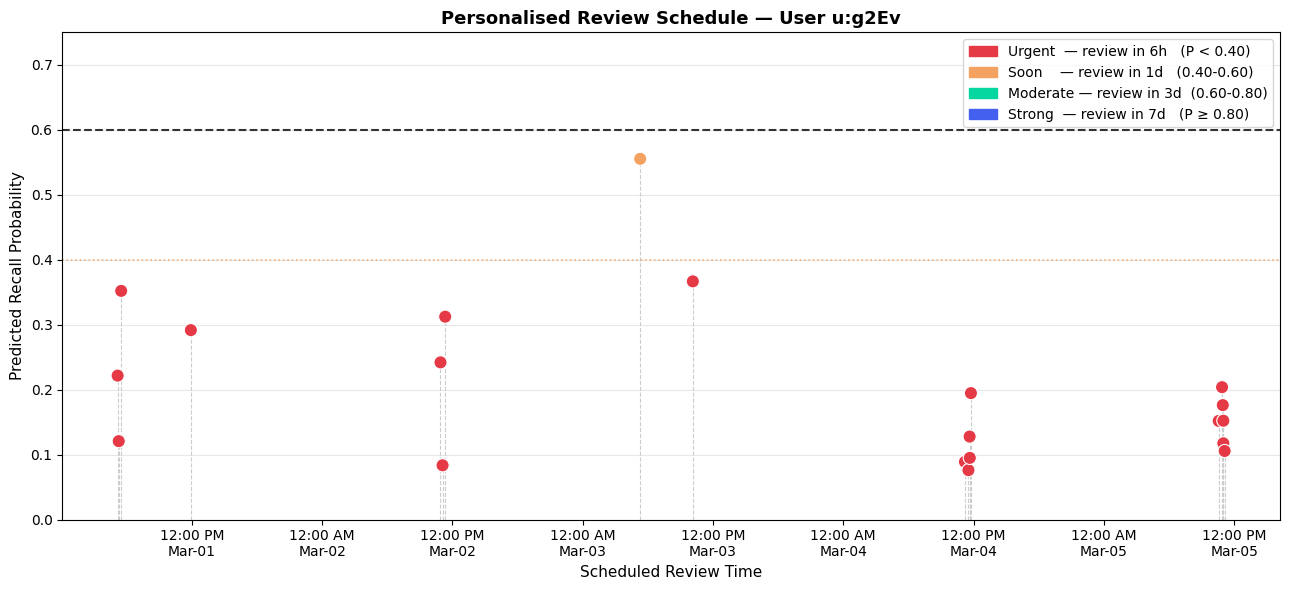

In [34]:
import matplotlib.patches as mpatches
import matplotlib.dates as mdates

fig, ax = plt.subplots(figsize=(13, 6))

# Colour each point by urgency bucket
colors = one_user_schedule['predicted_recall_prob'].apply(
    lambda p: '#E63946' if p < 0.40 else
              '#F4A261' if p < 0.60 else
              '#06D6A0' if p < 0.80 else '#4361EE'
)

# Scatter — items are independent, not a sequence
ax.scatter(
    one_user_schedule['next_review_time'],
    one_user_schedule['predicted_recall_prob'],
    c=colors, s=90, zorder=5, edgecolors='white', linewidth=0.8
)

# Vertical stems for readability
for _, row in one_user_schedule.iterrows():
    ax.vlines(
        x=row['next_review_time'],
        ymin=0,
        ymax=row['predicted_recall_prob'],
        colors='#CCCCCC', linewidth=0.8, linestyle='--'
    )

# Threshold lines
ax.axhline(y=0.6, color='#333333', linewidth=1.5,
           linestyle='--', label='Recall threshold (0.6)')
ax.axhline(y=0.4, color='#F4A261', linewidth=1.2,
           linestyle=':', alpha=0.8, label='Urgent threshold (0.4)')

ax.xaxis.set_major_formatter(
    mdates.DateFormatter('%I:%M %p\n%b-%d')
)

# Legend
patches = [
    mpatches.Patch(color='#E63946', label='Urgent  — review in 6h   (P < 0.40)'),
    mpatches.Patch(color='#F4A261', label='Soon    — review in 1d   (0.40-0.60)'),
    mpatches.Patch(color='#06D6A0', label='Moderate — review in 3d  (0.60-0.80)'),
    mpatches.Patch(color='#4361EE', label='Strong  — review in 7d   (P ≥ 0.80)'),
]
ax.legend(handles=patches, fontsize=10, loc='upper right')

one_userr = 'u:g2Ev'
ax.set_title(f"Personalised Review Schedule — User {one_userr}",
             fontsize=13, fontweight='bold')
ax.set_xlabel("Scheduled Review Time", fontsize=11)
ax.set_ylabel("Predicted Recall Probability", fontsize=11)
ax.set_ylim(0, 0.75)
ax.grid(True, axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

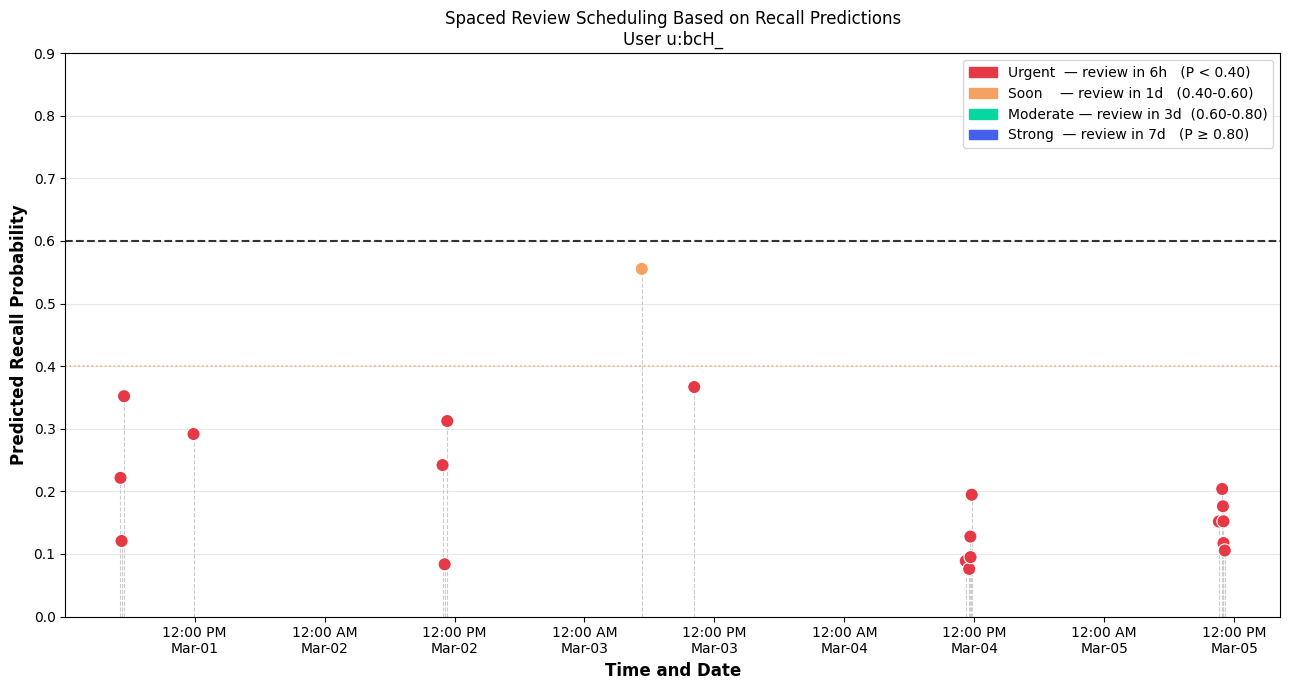

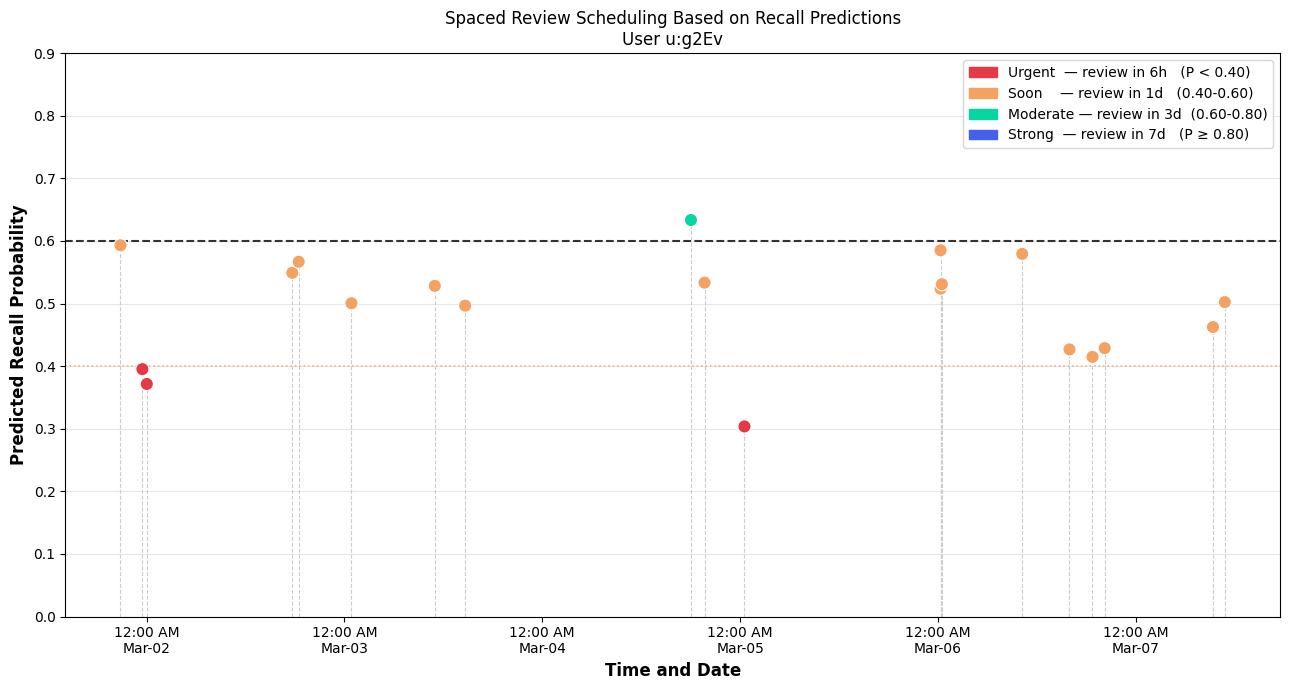

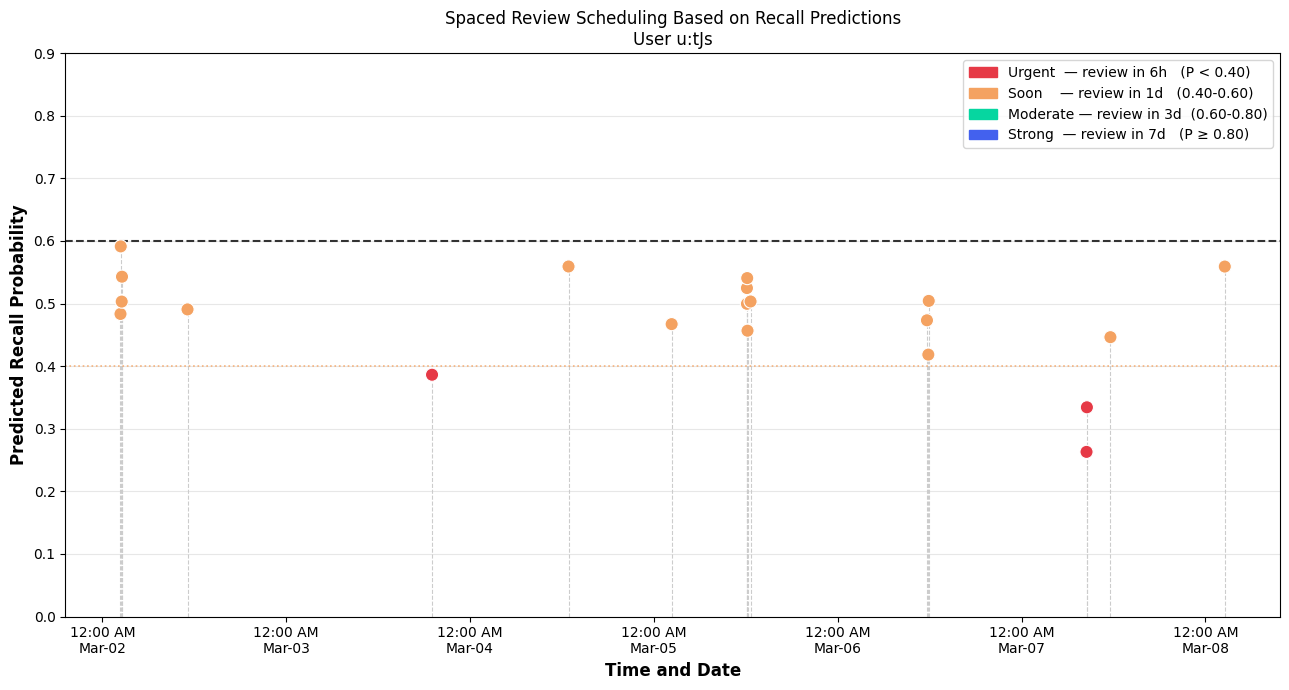

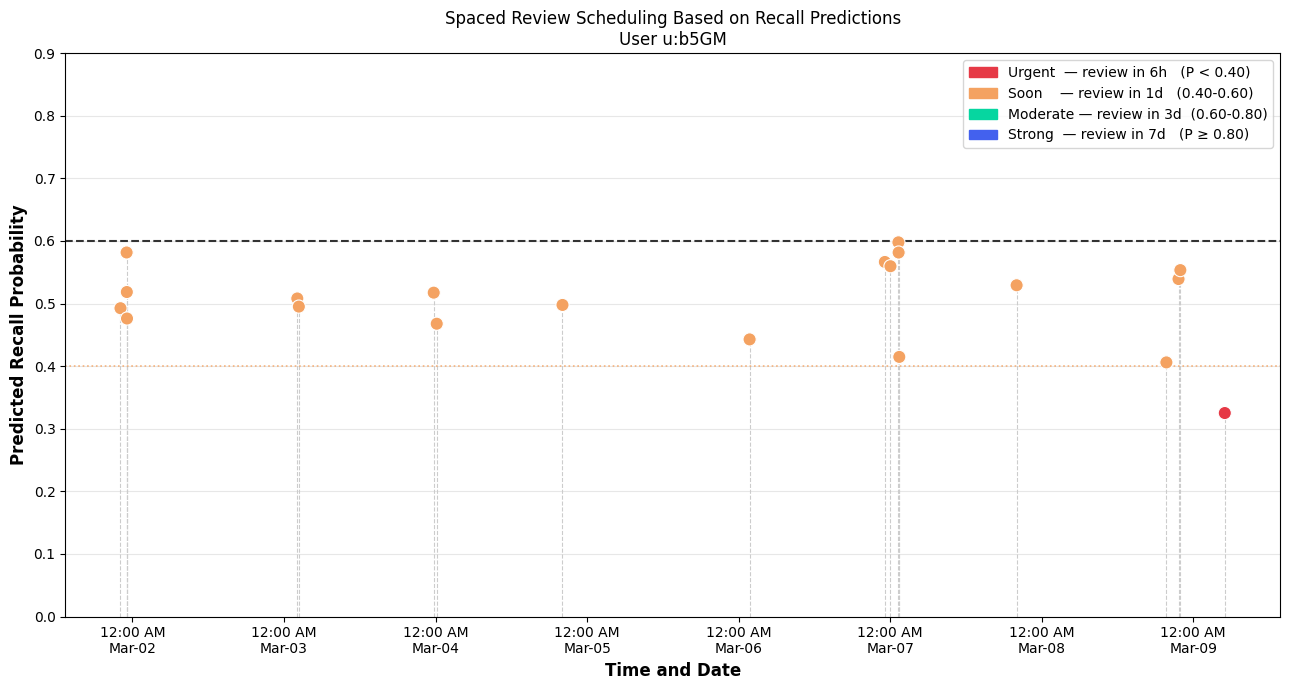

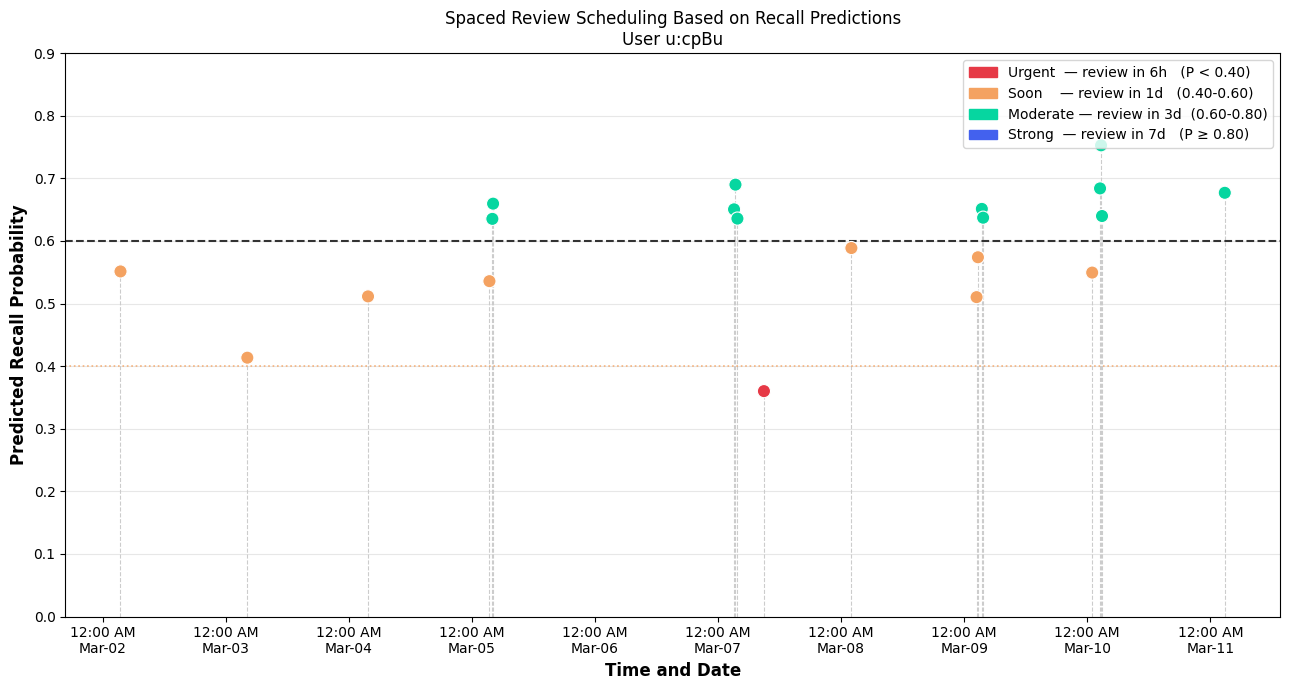

In [37]:
top_users = test_df['user_id'].value_counts().head(5).index

for uid in top_users:
    user_schedule = test_df[test_df['user_id'] == uid].copy()
    user_schedule = user_schedule.sort_values('next_review_time').head(20)

    fig, ax = plt.subplots(figsize=(13, 7))

    colors = user_schedule['predicted_recall_prob'].apply(
        lambda p: '#E63946' if p < 0.40 else
                  '#F4A261' if p < 0.60 else
                  '#06D6A0' if p < 0.80 else '#4361EE'
    )

    ax.scatter(user_schedule['next_review_time'],
               user_schedule['predicted_recall_prob'],
               c=colors, s=90, zorder=5, edgecolors='white', linewidth=0.8)

    for _, row in user_schedule.iterrows():
        ax.vlines(x=row['next_review_time'], ymin=0,
                  ymax=row['predicted_recall_prob'],
                  colors='#CCCCCC', linewidth=0.8, linestyle='--')

    ax.axhline(y=0.6, color='#333333', linewidth=1.5, linestyle='--')
    ax.axhline(y=0.4, color='#F4A261', linewidth=1.2, linestyle=':', alpha=0.8)

    ax.xaxis.set_major_formatter(
    mdates.DateFormatter('%I:%M %p\n%b-%d')
    )

    ax.legend(handles=patches, fontsize=10, loc='upper right')

    # ax.set_title(f"Personalised Review Schedule — User {uid}",
    #              fontsize=12, fontweight='bold')
    ax.set_title(f'Spaced Review Scheduling Based on Recall Predictions\nUser {uid}')
    ax.set_xlabel("Time and Date", fontsize=12, fontweight='bold')
    ax.set_ylabel("Predicted Recall Probability", fontsize=12, fontweight='bold')
    ax.set_ylim(0, 0.9)
    ax.grid(True, axis='y', alpha=0.3)
    plt.tight_layout()
    plt.show()

Global fit  →  b=28.607  c=0.000

User u:bcH_  →  mean_p=0.188  b_user=30.549  c_user=0.0000  rf_scale=1.375


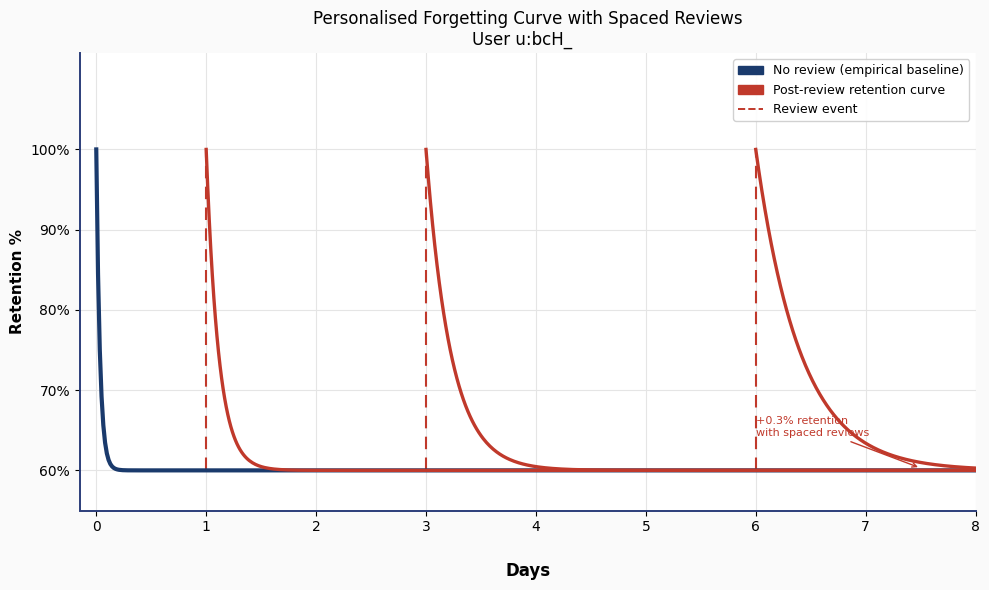

Saved → forgetting_curve_ubcH_.png

User u:g2Ev  →  mean_p=0.500  b_user=17.427  c_user=0.0000  rf_scale=2.001


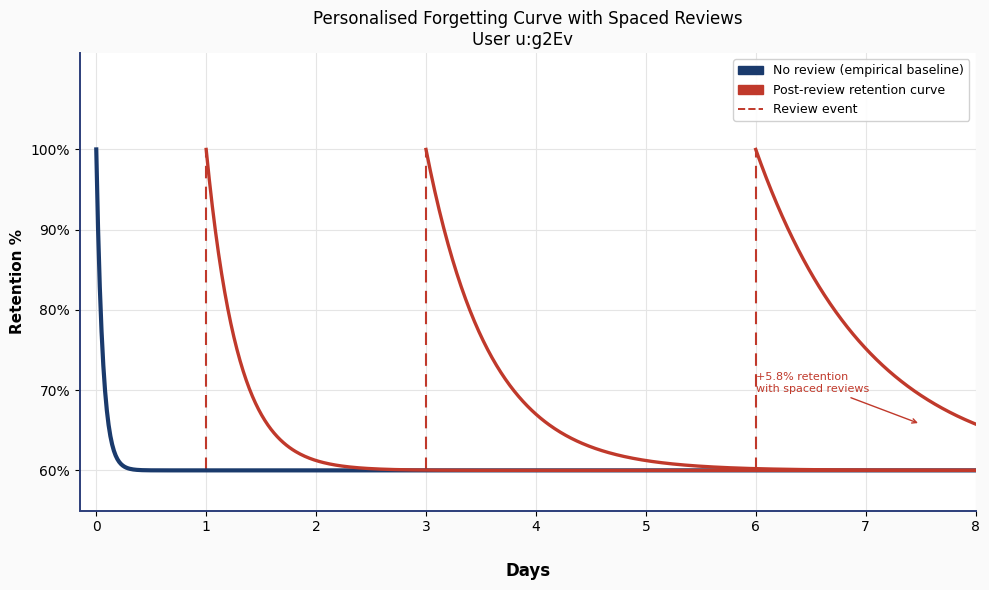

Saved → forgetting_curve_ug2Ev.png

User u:tJs  →  mean_p=0.452  b_user=15.524  c_user=0.0000  rf_scale=1.905


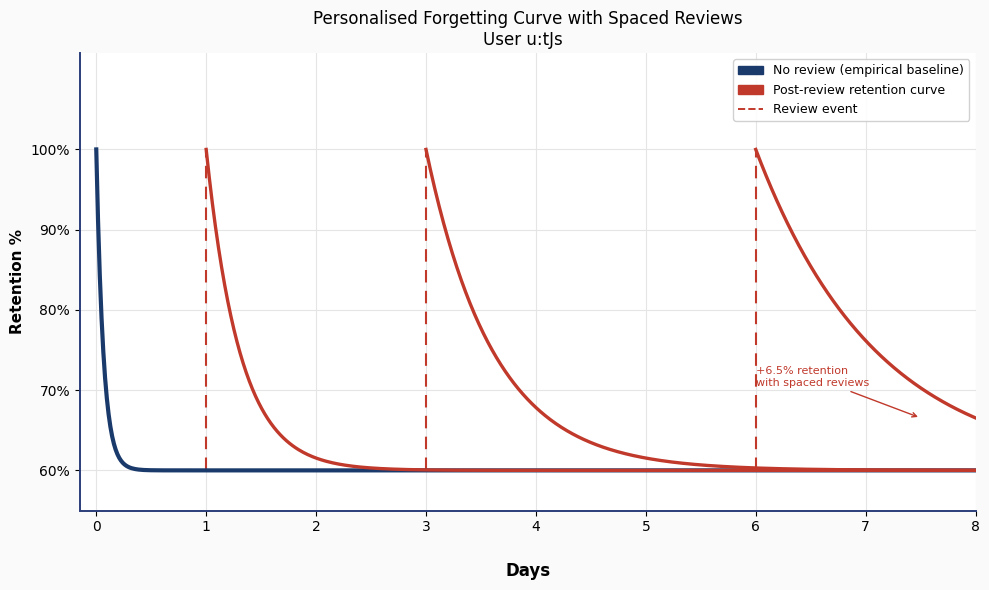

Saved → forgetting_curve_utJs.png

User u:b5GM  →  mean_p=0.504  b_user=18.623  c_user=0.0000  rf_scale=2.008


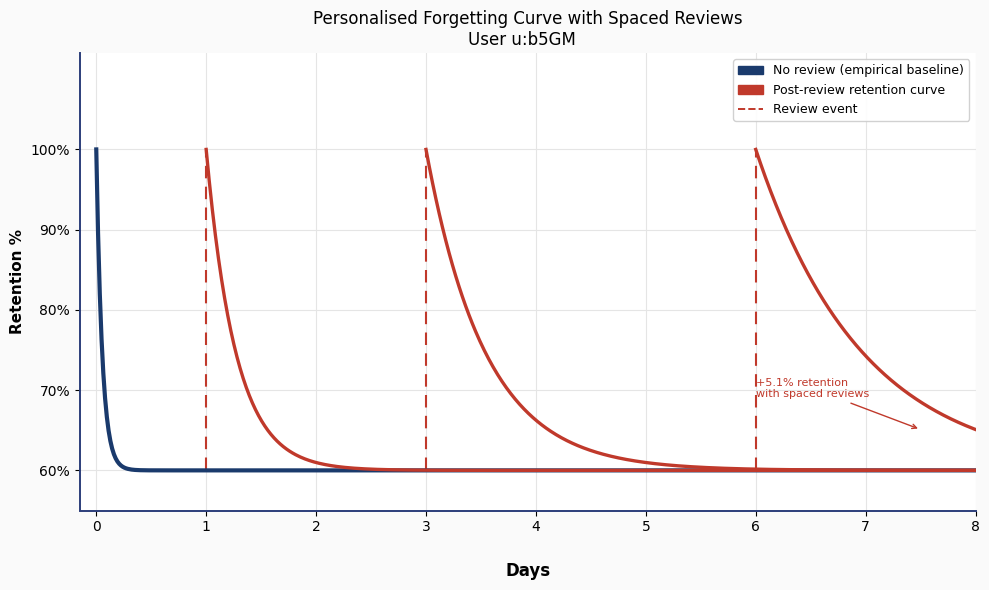

Saved → forgetting_curve_ub5GM.png

User u:cpBu  →  mean_p=0.618  b_user=14.279  c_user=0.0000  rf_scale=2.236


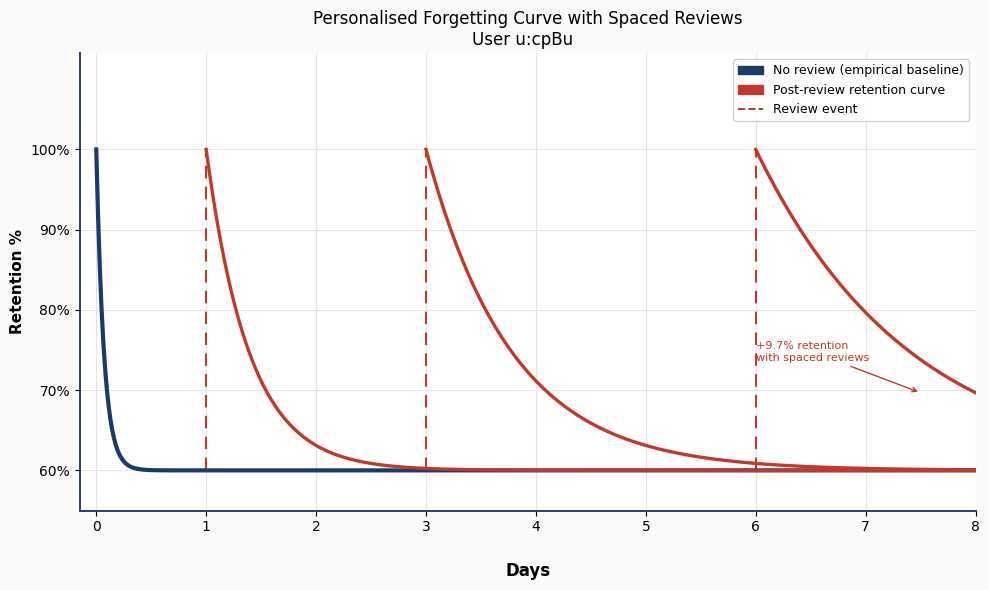

Saved → forgetting_curve_ucpBu.png


In [61]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from scipy.optimize import curve_fit

# decay model 
def decay_model(t, b, c):
    """R(t) = (1-c)*exp(-b*t) + c"""
    return (1.0 - c) * np.exp(-b * t) + c


# fit global anchor from shared forgetting_curve 
emp_vals     = forgetting_curve.values.astype(float)
bin_mids_log = np.array([iv.mid for iv in forgetting_curve.index])
bin_days     = np.expm1(bin_mids_log) / 24.0          # log1p-hours → days

valid    = (emp_vals > 0) & np.isfinite(emp_vals) & (bin_days >= 0) & (bin_days <= 8)
x_global = bin_days[valid]
y_global = emp_vals[valid] / emp_vals[valid][0]        # normalise to start at 1.0

try:
    popt, _ = curve_fit(
        decay_model, x_global, y_global,
        p0=[1.5, 0.05],
        bounds=([0.01, 0.0], [50.0, 0.5]),
        maxfev=8000
    )
    b_global, c_global = popt
except Exception:
    b_global, c_global = 1.5, 0.05

print(f"Global fit  →  b={b_global:.3f}  c={c_global:.3f}")


# per-user empirical fit using their own sample_data rows
def fit_user_decay(uid):
    """
    Fit decay model to this user's own time_gap_hours vs forgetting_curve
    values from sample_data. Falls back to global fit if too few points.
    """
    user_rows = sample_data_filtered[sample_data_filtered['user_id'] == uid].copy()

    if len(user_rows) < 10:
        return b_global, c_global   # fallback

    # bin the user's own time gaps (same log-scale as global)
    user_rows['log_tg'] = np.log1p(user_rows['time_gap_hours'])
    bins    = np.linspace(0, np.log1p(200), 30)
    user_rows['bin'] = pd.cut(user_rows['log_tg'], bins=bins)

    user_fc = user_rows.groupby('bin', observed=True)['forgetting_curve'].mean()
    if user_fc.empty or user_fc.isna().all():
        return b_global, c_global

    bin_mids = np.array([iv.mid for iv in user_fc.index])
    u_days   = np.expm1(bin_mids) / 24.0
    u_vals   = user_fc.values.astype(float)

    valid_u  = np.isfinite(u_vals) & (u_vals > 0) & (u_days >= 0) & (u_days <= 8)
    if valid_u.sum() < 4:
        return b_global, c_global

    xu = u_days[valid_u]
    yu = u_vals[valid_u] / u_vals[valid_u][0]

    try:
        popt_u, _ = curve_fit(
            decay_model, xu, yu,
            p0=[b_global, c_global],
            bounds=([0.01, 0.0], [50.0, 0.5]),
            maxfev=8000
        )
        return popt_u
    except Exception:
        return b_global, c_global


# plot 
T_MAX    = 8.0
N_SMOOTH = 500
t_smooth = np.linspace(0, T_MAX, N_SMOOTH)

REVIEW_DAYS  = [1.0, 3.0, 6.0]
# Base slowdown multipliers per review (cumulative strengthening)
BASE_MULTS   = [2.5, 5.0, 9.0]
REVIEW_COLOR = '#c0392b'
BASE_COLOR   = '#1a3a6c'

for uid in top_users:

    # per-user stats 
    user_sched = test_df[test_df['user_id'] == uid].copy()
    mean_p     = float(np.clip(user_sched['predicted_recall_prob'].mean(), 0.05, 0.95))

    # per-user decay fit
    b_u, c_u = fit_user_decay(uid)

    # personalise further: lower recall → faster decay
    b_user = b_u * (1.0 - mean_p * 0.6)
    c_user = c_u

    rf_scale = 1.0 + 2.0 * mean_p

    print(f"\nUser {uid}  →  mean_p={mean_p:.3f}  b_user={b_user:.3f}"
          f"  c_user={c_user:.4f}  rf_scale={rf_scale:.3f}")

    # build baseline
    baseline = decay_model(t_smooth, b_user, c_user)
    y_floor  = float(decay_model(T_MAX, b_user, c_user))
    # rescale so curve lives in 60–100% retention range
    def rescale(y):
        return 60.0 + (y - y_floor) / max(1.0 - y_floor, 1e-6) * 40.0

    y_base = rescale(baseline)

    # figure
    fig, ax = plt.subplots(figsize=(10, 6))
    fig.patch.set_facecolor('#FAFAFA')
    ax.set_facecolor('#FFFFFF')
    for sp in ax.spines.values():
        sp.set_edgecolor('#2c3e7a')
        sp.set_linewidth(1.4)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

    # baseline
    ax.plot(t_smooth, y_base,
            color=BASE_COLOR, lw=3.0, zorder=4,
            label='No review (empirical baseline)')

    # post-review curves
    for i, (t_rev, base_mult) in enumerate(zip(REVIEW_DAYS, BASE_MULTS)):
        b_rev  = b_user / (base_mult * rf_scale)    # personalised slowdown
        seg_t  = np.linspace(t_rev, T_MAX, N_SMOOTH)
        seg_y  = rescale(decay_model(seg_t - t_rev, b_rev, c_user))

        ax.plot(seg_t, seg_y,
                color=REVIEW_COLOR, lw=2.4, zorder=5,
                label=f'After review {i+1} (day {int(t_rev)})' if i == 0 else '_nolegend_')

        # dashed vertical
        ax.plot([t_rev, t_rev], [60, 100],
                color=REVIEW_COLOR, lw=1.5,
                linestyle='--', dashes=(6, 4), zorder=3)

    # retention gain annotation
    ret_baseline_end = float(y_base[-1])
    b_rev3   = b_user / (BASE_MULTS[2] * rf_scale)
    ret_rev3_end = float(rescale(
        decay_model(np.array([T_MAX - REVIEW_DAYS[2]]), b_rev3, c_user)[0]
    ))
    gain = ret_rev3_end - ret_baseline_end
    ax.annotate(
        f'+{gain:.1f}% retention\nwith spaced reviews',
        xy=(7.5, ret_rev3_end),
        xytext=(6.0, ret_rev3_end + 4),
        fontsize=8, color=REVIEW_COLOR,
        arrowprops=dict(arrowstyle='->', color=REVIEW_COLOR, lw=1.0)
    )

    # axes
    ax.set_xlim(-0.15, T_MAX)
    ax.set_ylim(55, 112)
    ax.set_xticks(range(0, int(T_MAX) + 1))
    ax.set_xticklabels([str(d) for d in range(0, int(T_MAX) + 1)], fontsize=10)
    ax.set_yticks([60, 70, 80, 90, 100])
    ax.set_yticklabels(['60%', '70%', '80%', '90%', '100%'], fontsize=10)
    ax.set_xlabel('Days', fontsize=12, fontweight='bold', labelpad=20)
    ax.set_ylabel('Retention %', fontsize=11,
                  fontweight='bold')
    ax.grid(True, color='#e5e5e5', linewidth=0.8, zorder=0)

    ax.set_title(
        f'Personalised Forgetting Curve with Spaced Reviews\nUser {uid}  '
    )

    # legend
    handles = [
        mpatches.Patch(color=BASE_COLOR,   label='No review (empirical baseline)'),
        mpatches.Patch(color=REVIEW_COLOR, label='Post-review retention curve'),
        plt.Line2D([0],[0], color=REVIEW_COLOR, lw=1.4,
                   linestyle='--', label='Review event'),
    ]
    ax.legend(handles=handles, fontsize=9, loc='upper right', framealpha=0.9)

    plt.tight_layout()
    fname = f'forgetting_curve_{uid.replace(":", "")}.png'
    plt.savefig(fname, dpi=150, bbox_inches='tight')
    plt.show()
    print(f"Saved → {fname}")